In [1]:
from __future__ import annotations

import os
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from PIL import Image
from transformers import AutoConfig, AutoImageProcessor, AutoModel

## 1. Load model and processor

In [2]:
MODEL_NAME = "facebook/dinov3-convnext-small-pretrain-lvd1689m"

config = AutoConfig.from_pretrained(MODEL_NAME)
processor = AutoImageProcessor.from_pretrained(MODEL_NAME, use_fast=True)
model = AutoModel.from_pretrained(MODEL_NAME)
model.eval()

print("Model type   :", type(model).__name__)
print("Config type  :", type(config).__name__)
print()
print(config)

config.json:   0%|          | 0.00/447 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/198M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/342 [00:00<?, ?it/s]

Model type   : DINOv3ConvNextModel
Config type  : DINOv3ConvNextConfig

DINOv3ConvNextConfig {
  "architectures": [
    "DINOv3ConvNextModel"
  ],
  "depths": [
    3,
    3,
    27,
    3
  ],
  "drop_path_rate": 0.0,
  "dtype": "float32",
  "hidden_act": "gelu",
  "hidden_sizes": [
    96,
    192,
    384,
    768
  ],
  "image_size": 224,
  "initializer_range": 0.02,
  "layer_norm_eps": 1e-06,
  "layer_scale_init_value": 1e-06,
  "model_type": "dinov3_convnext",
  "num_channels": 3,
  "out_features": [
    "stage4"
  ],
  "out_indices": [
    4
  ],
  "stage_names": [
    "stem",
    "stage1",
    "stage2",
    "stage3",
    "stage4"
  ],
  "transformers_version": "5.3.0"
}



In [ ]:
print("Processor config:")
print(f"  do_resize        : {processor.do_resize}")
print(f"  size             : {processor.size}")
print(f"  do_center_crop   : {processor.do_center_crop}")
print(f"  crop_size        : {processor.crop_size}")
print(f"  do_rescale       : {processor.do_rescale}")
print(f"  do_normalize     : {processor.do_normalize}")


## 2. Full model architecture

In [3]:
print(model)

DINOv3ConvNextModel(
  (stages): ModuleList(
    (0): DINOv3ConvNextStage(
      (downsample_layers): ModuleList(
        (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
        (1): DINOv3ConvNextLayerNorm((96,), eps=1e-06, elementwise_affine=True)
      )
      (layers): ModuleList(
        (0-2): 3 x DINOv3ConvNextLayer(
          (depthwise_conv): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (layer_norm): DINOv3ConvNextLayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (pointwise_conv1): Linear(in_features=96, out_features=384, bias=True)
          (activation_fn): GELUActivation()
          (pointwise_conv2): Linear(in_features=384, out_features=96, bias=True)
          (drop_path): Identity()
        )
      )
    )
    (1): DINOv3ConvNextStage(
      (downsample_layers): ModuleList(
        (0): DINOv3ConvNextLayerNorm((96,), eps=1e-06, elementwise_affine=True)
        (1): Conv2d(96, 192, kernel_size=(2, 2), stride=(2,

## 3. Named modules with parameter counts

In [4]:
total_params = sum(p.numel() for p in model.parameters())
print(f"{'Module':<60} {'Params':>12}")
print("-" * 74)
for name, module in model.named_modules():
    own_params = sum(p.numel() for p in module.parameters(recurse=False))
    if own_params > 0:
        print(f"{name:<60} {own_params:>12,}")
print("-" * 74)
print(f"{'TOTAL':<60} {total_params:>12,}")

Module                                                             Params
--------------------------------------------------------------------------
stages.0.downsample_layers.0                                        4,704
stages.0.downsample_layers.1                                          192
stages.0.layers.0                                                      96
stages.0.layers.0.depthwise_conv                                    4,800
stages.0.layers.0.layer_norm                                          192
stages.0.layers.0.pointwise_conv1                                  37,248
stages.0.layers.0.pointwise_conv2                                  36,960
stages.0.layers.1                                                      96
stages.0.layers.1.depthwise_conv                                    4,800
stages.0.layers.1.layer_norm                                          192
stages.0.layers.1.pointwise_conv1                                  37,248
stages.0.layers.1.pointwise_conv2    

## 4. Load a CrowdPose image and run inference

Image: 108777.jpg  size: (640, 426)  (W x H)


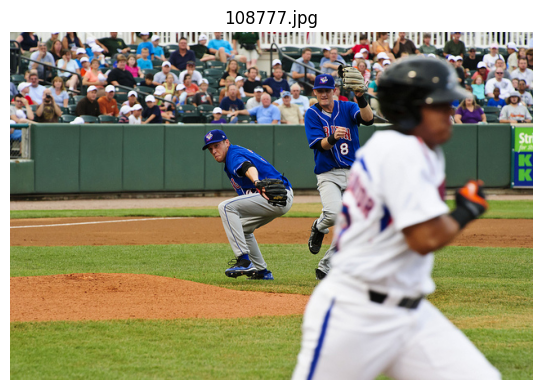

In [7]:
IMG_DIR = Path("/home/gasparyanartur/dev/pose-graph-diff/data/crowdpose/images")
img_path = next(IMG_DIR.glob("*.jpg"))

pil_image = Image.open(img_path).convert("RGB")
print(f"Image: {img_path.name}  size: {pil_image.size}  (W x H)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(pil_image)
ax.axis("off")
ax.set_title(img_path.name)
plt.tight_layout()
plt.show()

In [8]:
inputs = processor(images=pil_image, return_tensors="pt")
print("Processor output shapes:")
for k, v in inputs.items():
    print(f"  {k}: {tuple(v.shape)}")

with torch.inference_mode():
    outputs = model(**inputs, output_hidden_states=True)

print("\nOutput keys:", list(outputs.keys()))

Processor output shapes:
  pixel_values: (1, 3, 224, 224)

Output keys: ['last_hidden_state', 'pooler_output', 'hidden_states']


## 5. Hidden-state shapes per stage

In [9]:
hidden_states = outputs.hidden_states  # tuple of Tensors

print(f"Number of hidden states: {len(hidden_states)}")
print()
print(f"{'Index':<8} {'Shape':<30} {'Layout'}")
print("-" * 60)
for i, hs in enumerate(hidden_states):
    shape_str = str(tuple(hs.shape))
    layout = "(B, C, H, W)" if hs.ndim == 4 else f"ndim={hs.ndim}"
    print(f"{i:<8} {shape_str:<30} {layout}")

print()
if hasattr(outputs, "last_hidden_state") and outputs.last_hidden_state is not None:
    print("last_hidden_state shape:", tuple(outputs.last_hidden_state.shape))
if hasattr(outputs, "pooler_output") and outputs.pooler_output is not None:
    print("pooler_output shape    :", tuple(outputs.pooler_output.shape))

Number of hidden states: 5

Index    Shape                          Layout
------------------------------------------------------------
0        (1, 3, 224, 224)               (B, C, H, W)
1        (1, 96, 56, 56)                (B, C, H, W)
2        (1, 192, 28, 28)               (B, C, H, W)
3        (1, 384, 14, 14)               (B, C, H, W)
4        (1, 768, 7, 7)                 (B, C, H, W)

last_hidden_state shape: (1, 50, 768)
pooler_output shape    : (1, 768)


## 6. Mean-activation heatmaps per stage

For each 4-D hidden state (B, C, H, W) we compute the mean across channels
and visualise it alongside the original image.

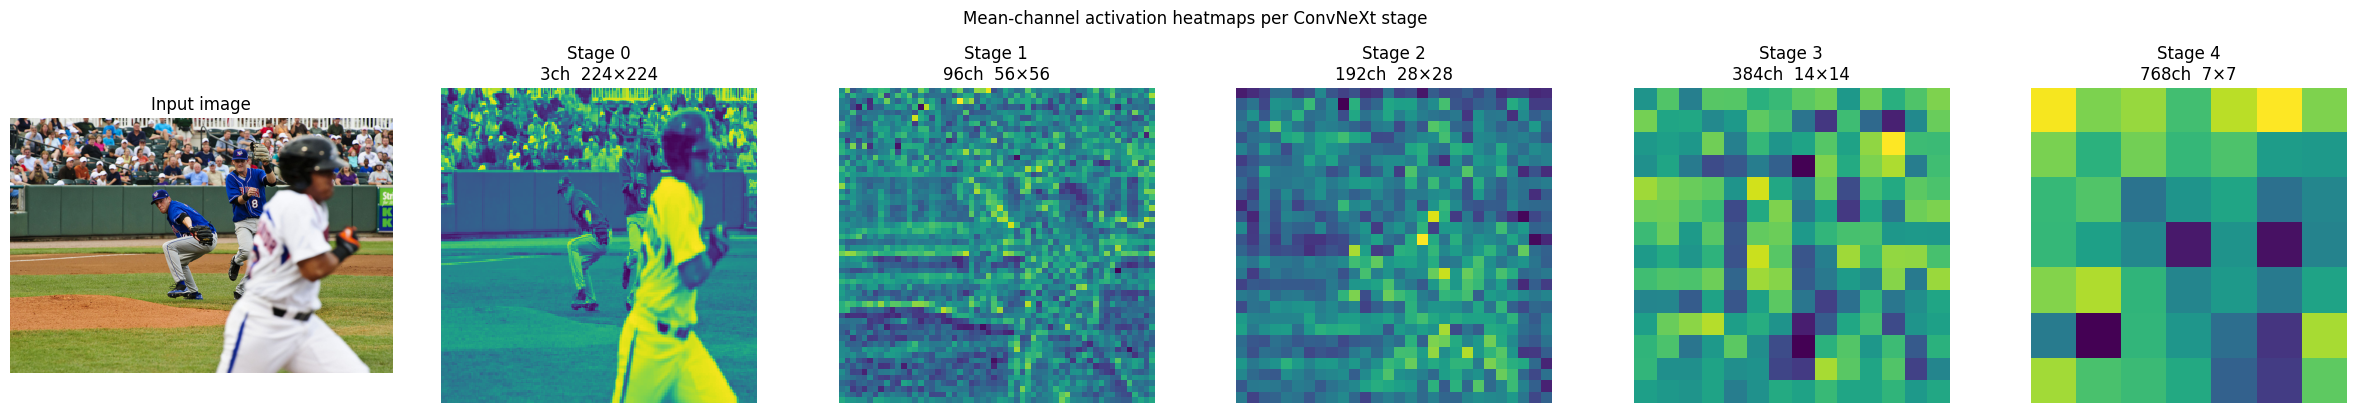

In [10]:
spatial_states = [(i, hs) for i, hs in enumerate(hidden_states) if hs.ndim == 4]

n = len(spatial_states)
fig, axes = plt.subplots(1, n + 1, figsize=(4 * (n + 1), 4))

axes[0].imshow(pil_image)
axes[0].set_title("Input image")
axes[0].axis("off")

for ax, (i, hs) in zip(axes[1:], spatial_states):
    # mean over channel dim → (H, W)
    heatmap = hs[0].mean(dim=0).cpu().float().numpy()
    # normalise to [0, 1] for display
    heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
    B, C, H, W = hs.shape
    ax.imshow(heatmap, cmap="viridis", interpolation="nearest")
    ax.set_title(f"Stage {i}\n{C}ch  {H}×{W}")
    ax.axis("off")

plt.suptitle("Mean-channel activation heatmaps per ConvNeXt stage", y=1.02)
plt.tight_layout()
plt.show()

## 7. Summary table

In [13]:
input_h, input_w = inputs["pixel_values"].shape[-2:]

# stage 0 = raw input tensor, stages 1-4 = actual ConvNeXt encoder stages
stage_labels = {
    0: ("input",  "raw pixel input (not a backbone stage)"),
    1: ("stage1", "spatial  — high-res (1/4 downsampled)"),
    2: ("stage2", "spatial  — mid-res  (1/8 downsampled)"),
    3: ("stage3", "semantic — low-res  (1/16 downsampled)"),
    4: ("stage4", "semantic — bottleneck (1/32 downsampled)"),
}

print(f"Input resolution: {input_h} x {input_w}")
print()
print(f"{'#':<4} {'Name':<8} {'Shape':<24} {'C':<8} {'H x W':<12} {'DS':<8} Intended use")
print("-" * 84)

for i, hs in enumerate(hs for hs in hidden_states if hs.ndim == 4):
    B, C, H, W = hs.shape
    ds = f"1/{input_h // H}x" if input_h // H > 1 else "1x"
    label, use = stage_labels.get(i, (f"stage{i}", "—"))
    print(f"{i:<4} {label:<8} {str(tuple(hs.shape)):<24} {C:<8} {str(H) + 'x' + str(W):<12} {ds:<8} {use}")

if hasattr(outputs, "pooler_output") and outputs.pooler_output is not None:
    po = outputs.pooler_output
    print(f"{'—':<4} {'pool':<8} {str(tuple(po.shape)):<24} {po.shape[-1]:<8} {'1x1':<12} {'global':<8} global (GAP over stage4)")

print()
lhs = outputs.last_hidden_state
print(f"last_hidden_state: {tuple(lhs.shape)}")
extra = lhs.shape[1] - (7 * 7)
print(f"  7x7 spatial tokens = 49, extra tokens = {extra}")
print(f"  (ConvNeXt flattens stage4 7x7 -> 49 patch tokens + {extra} prepended summary token)")

Input resolution: 224 x 224

#    Name     Shape                    C        H x W        DS       Intended use
------------------------------------------------------------------------------------
0    input    (1, 3, 224, 224)         3        224x224      1x       raw pixel input (not a backbone stage)
1    stage1   (1, 96, 56, 56)          96       56x56        1/4x     spatial  — high-res (1/4 downsampled)
2    stage2   (1, 192, 28, 28)         192      28x28        1/8x     spatial  — mid-res  (1/8 downsampled)
3    stage3   (1, 384, 14, 14)         384      14x14        1/16x    semantic — low-res  (1/16 downsampled)
4    stage4   (1, 768, 7, 7)           768      7x7          1/32x    semantic — bottleneck (1/32 downsampled)
—    pool     (1, 768)                 768      1x1          global   global (GAP over stage4)

last_hidden_state: (1, 50, 768)
  7x7 spatial tokens = 49, extra tokens = 1
  (ConvNeXt flattens stage4 7x7 -> 49 patch tokens + 1 prepended summary token)


## 8. Resize-only preprocessing (no center-crop)

The default processor resizes the short side to 256 then center-crops to 224×224,
discarding image edges. Here we disable the crop and resize the short side to 224
directly, preserving the original aspect ratio.


do_center_crop : False
size           : {'shortest_edge': 224}

original image  (W x H): (640, 426)
pixel_values shape     : (1, 3, 224, 336)


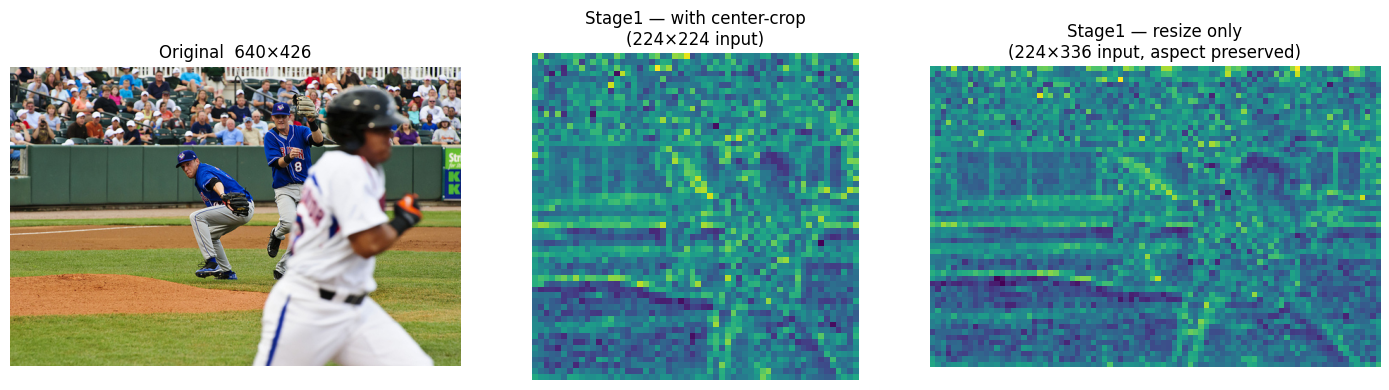

In [14]:
processor_nocrop = AutoImageProcessor.from_pretrained(
    MODEL_NAME,
    use_fast=True,
    do_center_crop=False,
    size={"shortest_edge": 224},
)

print("do_center_crop :", processor_nocrop.do_center_crop)
print("size           :", processor_nocrop.size)

inputs_nocrop = processor_nocrop(images=pil_image, return_tensors="pt")
print("\noriginal image  (W x H):", pil_image.size)
print("pixel_values shape     :", tuple(inputs_nocrop["pixel_values"].shape))

with torch.inference_mode():
    outputs_nocrop = model(**inputs_nocrop, output_hidden_states=True)

# --- side-by-side: original | stage1 with crop | stage1 without crop ---
def norm(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

stage1_crop   = outputs.hidden_states[1][0].mean(0).cpu().float().numpy()
stage1_nocrop = outputs_nocrop.hidden_states[1][0].mean(0).cpu().float().numpy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(pil_image)
axes[0].set_title(f"Original  {pil_image.size[0]}×{pil_image.size[1]}")
axes[1].imshow(norm(stage1_crop), cmap="viridis", interpolation="nearest")
h_crop, w_crop = inputs["pixel_values"].shape[-2:]
axes[1].set_title(f"Stage1 — with center-crop\n({h_crop}×{w_crop} input)")
axes[2].imshow(norm(stage1_nocrop), cmap="viridis", interpolation="nearest")
h_nc, w_nc = inputs_nocrop["pixel_values"].shape[-2:]
axes[2].set_title(f"Stage1 — resize only\n({h_nc}×{w_nc} input, aspect preserved)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
